# Fraud Detection in Electricity and Gas Consumption Challenge

This is a simple starter notebook based on the tutorial prepared by Joy Wawira. Check out the article [here](https://zindi.africa/learn/fraud-detection-in-electricity-and-gas-consumption-challenge-tutorial) for a more detailed description of the steps taken.

This notebook covers:
- Downloading the data straight from Zindi and onto colab
- Loading the data and carrying out simple EDA to understand the data and prepare for modelling 
- Preprocessing the data and feature engineering 
- Creating a simple LGBM model and predicting on the test set
- Prepare submission file and save as csv
- Some tips on how to improve model performance and your score

# Pre-Requisites

In [1]:
DATA_DIR = './data'

TRAIN_DIR = f'{DATA_DIR}/train'
TEST_DIR = f'{DATA_DIR}/test'

OUTPUT_DIR = f'{DATA_DIR}/output'

# Data Prep

## Import Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm
from lightgbm import LGBMClassifier
import numpy as np

import warnings
warnings.simplefilter('ignore')

## Read the Data

In [3]:
client_train = pd.read_csv(f'{TRAIN_DIR}/client_train.csv', low_memory=False)
invoice_train = pd.read_csv(f'{TRAIN_DIR}/invoice_train.csv', low_memory=False)

client_test = pd.read_csv(f'{TEST_DIR}/client_test.csv', low_memory=False)
invoice_test = pd.read_csv(f'{TEST_DIR}/invoice_test.csv', low_memory=False)
#sample_submission = pd.read_csv(f'{DATA_DIR}/SampleSubmission.csv', low_memory=False)

## Data Understanding

In [4]:
#compare size of the various datasets
print(client_train.shape, invoice_train.shape,client_test.shape, invoice_test.shape )

(135493, 6) (4476749, 16) (58069, 5) (1939730, 16)


In [5]:
#print top rows of dataset
invoice_train.head(300)


,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,train_Client_100003,2012-06-27,11,586800,0,467,9,1,254,0,0,0,0,254,4,ELEC
296,train_Client_100003,2012-01-11,11,586800,0,467,9,1,1200,1722,0,0,254,3176,4,ELEC
297,train_Client_100004,2007-02-20,11,1052129,0,203,6,1,20,0,0,0,20,40,4,ELEC
298,train_Client_100004,2006-10-18,11,1052129,0,203,6,1,20,0,0,0,0,20,4,ELEC


In [6]:
client_train.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


In [7]:
invoice_train["counter_statue"].unique()

<StringArray>
['0', '1', '5', '4', '3', '2', '769', 'A', '618', '269375', '46', '420']
Length: 12, dtype: str

In [8]:
invoice_train["counter_code"].unique()

array([203, 207, 413,   5, 467, 202, 420, 410,  10, 483,  25, 433, 407,
       204, 214, 442, 453, 506, 450, 403, 333, 201, 102, 305, 210, 101,
       532,  40, 310, 565, 600, 307, 303, 222,  65,   0, 227, 325,  16,
       317, 367,   1])

In [9]:
invoice_train["reading_remarque"].value_counts()

reading_remarque
6      2230939
9      1416992
8       828123
7          661
203         15
413         12
207          6
5            1
Name: count, dtype: int64

In [10]:
invoice_train["counter_type"].value_counts()

counter_type
ELEC    3079406
GAZ     1397343
Name: count, dtype: int64

In [11]:
#invoice_train["counter_coefficient"].unique()
invoice_train["months_number"].nunique()

1370

In [12]:
#print top rows of dataset
client_train.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


In [13]:
client_train["client_catg"].unique()

array([11, 12, 51])

In [14]:
#Get a summary for all numerical columns
invoice_train.describe()

,tarif_type,counter_number,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number
count,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06,4.476749e+06
mean,2.012804e+01,1.230587e+11,1.724884e+02,7.321702e+00,1.003040e+00,4.109795e+02,1.093225e+02,2.030620e+01,5.292588e+01,1.776700e+04,1.834970e+04,4.483095e+01
std,1.347256e+01,1.657267e+12,1.338871e+02,1.571654e+00,3.083466e-01,7.573080e+02,1.220123e+03,1.574239e+02,8.754725e+02,4.036693e+04,4.095321e+04,3.128335e+03
min,8.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.100000e+01,1.211080e+05,5.000000e+00,6.000000e+00,1.000000e+00,7.900000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.791000e+03,2.056000e+03,4.000000e+00
50%,1.100000e+01,4.945610e+05,2.030000e+02,8.000000e+00,1.000000e+00,2.740000e+02,0.000000e+00,0.000000e+00,0.000000e+00,7.690000e+03,8.192000e+03,4.000000e+00
75%,4.000000e+01,1.115161e+06,2.070000e+02,9.000000e+00,1.000000e+00,6.000000e+02,0.000000e+00,0.000000e+00,0.000000e+00,2.166000e+04,2.234300e+04,4.000000e+00
max,4.500000e+01,2.798115e+13,6.000000e+02,4.130000e+02,5.000000e+01,9.999100e+05,9.990730e+05,6.449200e+04,5.479460e+05,2.800280e+06,2.870972e+06,6.366240e+05


In [15]:
#Get a summary for all numerical columns
client_train.describe()

,disrict,client_catg,region,target
count,135493.000000,135493.000000,135493.000000,135493.000000
mean,63.511222,11.512506,206.159809,0.055841
std,3.354400,4.423761,104.207044,0.229614
min,60.000000,11.000000,101.000000,0.000000
25%,62.000000,11.000000,103.000000,0.000000
50%,62.000000,11.000000,107.000000,0.000000
75%,69.000000,11.000000,307.000000,0.000000
max,69.000000,51.000000,399.000000,1.000000


In [16]:
#Get concise information of each column in dataset
invoice_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 4476749 entries, 0 to 4476748
Data columns (total 16 columns):
 #   Column                Dtype
---  ------                -----
 0   client_id             str  
 1   invoice_date          str  
 2   tarif_type            int64
 3   counter_number        int64
 4   counter_statue        str  
 5   counter_code          int64
 6   reading_remarque      int64
 7   counter_coefficient   int64
 8   consommation_level_1  int64
 9   consommation_level_2  int64
 10  consommation_level_3  int64
 11  consommation_level_4  int64
 12  old_index             int64
 13  new_index             int64
 14  months_number         int64
 15  counter_type          str  
dtypes: int64(12), str(4)
memory usage: 546.5 MB


In [17]:
#Get concise information of each column in dataset
client_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 135493 entries, 0 to 135492
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   disrict        135493 non-null  int64  
 1   client_id      135493 non-null  str    
 2   client_catg    135493 non-null  int64  
 3   region         135493 non-null  int64  
 4   creation_date  135493 non-null  str    
 5   target         135493 non-null  float64
dtypes: float64(1), int64(3), str(2)
memory usage: 6.2 MB


In [18]:
client_train["disrict"].value_counts()

disrict
62    40353
69    34231
60    31922
63    28987
Name: count, dtype: int64

In [19]:
#Getting unique values on the invoice train data
for col in invoice_train.columns:
    print(f"{col} - {invoice_train[col].nunique()}")

client_id - 135493
invoice_date - 8275
tarif_type - 17
counter_number - 201893
counter_statue - 12
counter_code - 42
reading_remarque - 8
counter_coefficient - 16
consommation_level_1 - 8295
consommation_level_2 - 12576
consommation_level_3 - 2253
consommation_level_4 - 12075
old_index - 155648
new_index - 157980
months_number - 1370
counter_type - 2


In [20]:
#Getting unique values on the invoice train data
for col in client_train.columns:
    print(f"{col} - {client_train[col].nunique()}")

disrict - 4
client_id - 135493
client_catg - 3
region - 25
creation_date - 8088
target - 2


In [21]:
#check for missing values
invoice_train.isnull().sum()

client_id               0
invoice_date            0
tarif_type              0
counter_number          0
counter_statue          0
counter_code            0
reading_remarque        0
counter_coefficient     0
consommation_level_1    0
consommation_level_2    0
consommation_level_3    0
consommation_level_4    0
old_index               0
new_index               0
months_number           0
counter_type            0
dtype: int64

In [22]:
#check for missing values
client_train.isnull().sum()

disrict          0
client_id        0
client_catg      0
region           0
creation_date    0
target           0
dtype: int64

No missing values in train set

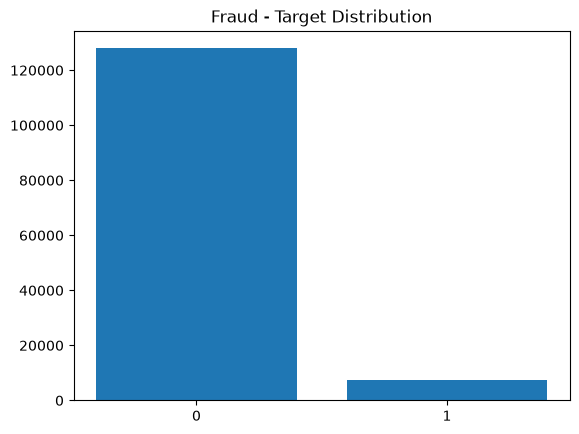

In [23]:
#Visualize fraudulent activities
fraudactivities = client_train.groupby(['target'])['client_id'].count()
plt.bar(x=fraudactivities.index, height=fraudactivities.values, tick_label = [0,1])
plt.title('Fraud - Target Distribution')
plt.show()

Target is highly imbalanced with fewer cases of fraudulent activities

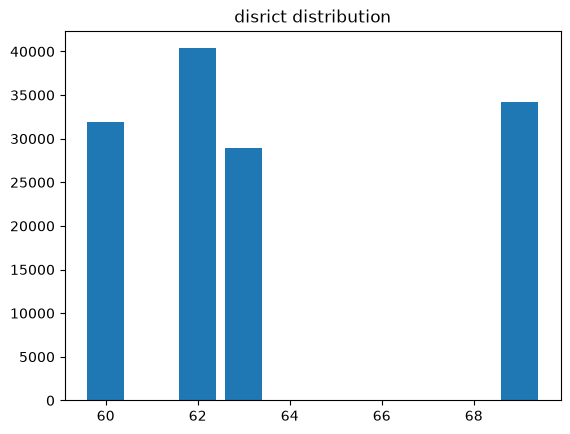

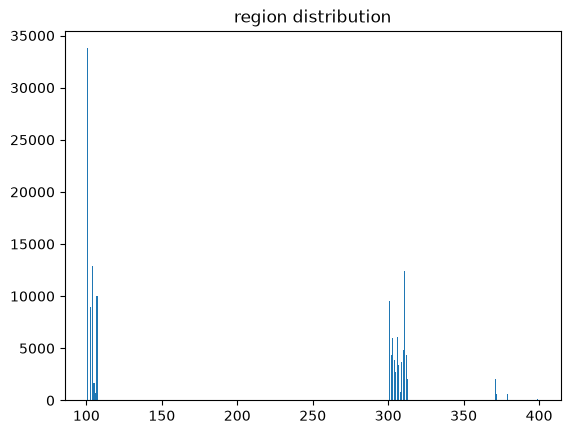

In [24]:
#Visualize client distribution across districts and regions
for col in ['disrict','region']:
    region = client_train.groupby([col])['client_id'].count()
    plt.bar(x=region.index, height=region.values)
    plt.title(col+' distribution')
    plt.show()

In [25]:
# merging tables together 

merged_train = pd.merge(invoice_train,client_train[['client_id','disrict', 'region', 'client_catg', 'target']], on='client_id',
    how='left',
    validate='many_to_one'
)

In [26]:
merged_train.columns

Index(['client_id', 'invoice_date', 'tarif_type', 'counter_number',
       'counter_statue', 'counter_code', 'reading_remarque',
       'counter_coefficient', 'consommation_level_1', 'consommation_level_2',
       'consommation_level_3', 'consommation_level_4', 'old_index',
       'new_index', 'months_number', 'counter_type', 'disrict', 'region',
       'client_catg', 'target'],
      dtype='str')

In [27]:
(merged_train["months_number"] >12).sum()/(merged_train["months_number"] >0).sum()

np.float64(0.005370194027046872)

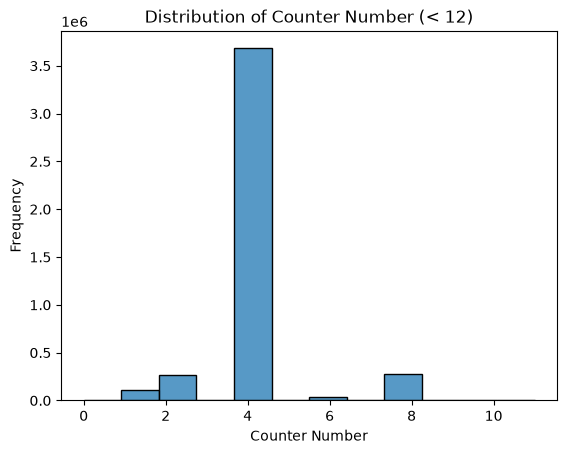

In [28]:
import seaborn as sns
sns.histplot(
    data=merged_train[merged_train["months_number"] < 12],
    x="months_number",
    bins=12
)

plt.xlabel("Counter Number")
plt.ylabel("Frequency")
plt.title("Distribution of Counter Number (< 12)")
plt.show()

In [29]:
# sorting based on client_id + data
merged_train['invoice_date'] = pd.to_datetime(merged_train['invoice_date'])
 
merged_train = merged_train.sort_values(
    by=['client_id', 'invoice_date'],
    ascending=[True, True]
).reset_index(drop=True)

merged_train['consumption_amount'] = merged_train['new_index']-merged_train['old_index']
merged_train['invoice_month'] = merged_train['invoice_date'].dt.month

# dropping unneccessary columns
merged_train = merged_train.drop(columns=["counter_number", "old_index", "new_index"])

# To drom column with months_number > 12
merged_train = merged_train[merged_train["months_number"] <= 12].copy()
merged_train = merged_train.reset_index(drop=True)

#merged_train.head(5)
#consum_amount=merged_train[""]

In [30]:
# To check it out if there is significant difference in consumption in different months
merged_train["monthly_consumption"] = (merged_train["consumption_amount"] / merged_train["months_number"])
seasonal_cycle_cons = (merged_train.groupby(["counter_type", "invoice_month", "client_catg"])["monthly_consumption"].mean().reset_index())
seasonal_cycle_cons

,counter_type,invoice_month,client_catg,monthly_consumption
0,ELEC,1,11,149.462635
1,ELEC,1,12,142.909733
2,ELEC,1,51,1212.932907
3,ELEC,2,11,189.132698
4,ELEC,2,12,324.951610
...,...,...,...,...
67,GAZ,11,12,48.682535
68,GAZ,11,51,545.858981
69,GAZ,12,11,37.045887
70,GAZ,12,12,48.122398


<Figure size 1000x500 with 0 Axes>

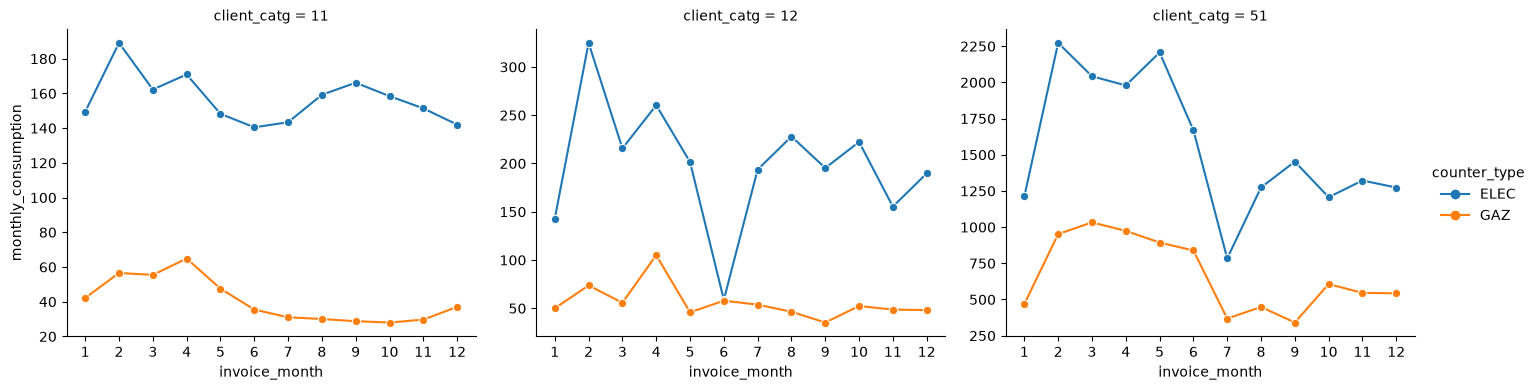

In [31]:


plt.figure(figsize=(10, 5))

sns.relplot(
    data=seasonal_cycle_cons,
    x="invoice_month",
    y="monthly_consumption",
    hue="counter_type",
    col="client_catg",
    kind="line",
    marker="o",
    height=4,
    aspect=1.2,
    facet_kws={"sharey": False}
)

plt.xticks(range(1, 13))
plt.show()

In [32]:
seasonal_cycle_cons_dist = (merged_train.groupby(["region", "client_catg", "counter_type", "invoice_month"])["monthly_consumption"].mean().reset_index())

In [33]:
# Incorporating seasonal range in the merge_train. 
seasonal_benchmark = (seasonal_cycle_cons_dist.groupby(["region","client_catg", "counter_type"])["monthly_consumption"].agg(["max", "min", "mean"]).reset_index())

seasonal_benchmark["seasonal_range"] = ((seasonal_benchmark["max"] - seasonal_benchmark["min"]) /
seasonal_benchmark["mean"])

seasonal_benchmark


,region,client_catg,counter_type,max,min,mean,seasonal_range
0,101,11,ELEC,202.713464,146.065188,173.911849,0.325730
1,101,11,GAZ,46.325283,28.261116,35.881485,0.503440
2,101,12,ELEC,416.417861,169.774424,265.237106,0.929898
3,101,12,GAZ,117.558109,48.213213,77.084427,0.899597
4,101,51,ELEC,2454.674911,-507.538534,1758.734365,1.684287
...,...,...,...,...,...,...,...
128,379,12,GAZ,24.375000,4.750000,15.625000,1.256000
129,379,51,ELEC,146.791667,0.000000,83.420833,1.759652
130,399,11,ELEC,202.073214,64.805556,114.565043,1.198164
131,399,11,GAZ,21.711538,7.437500,15.108061,0.944796


In [34]:
# Keep only necessary columns
cols = ["client_id", "counter_type"]

df = merged_train[
    cols + ["monthly_consumption"]
].dropna().sort_values("monthly_consumption")

# Average of 3 smallest values
min_cons = (
    df.groupby(cols).head(3)
    .groupby(cols)["monthly_consumption"].mean()
)

# Average of 3 largest values
max_cons = (
    df.groupby(cols).tail(3)
    .groupby(cols)["monthly_consumption"].mean()
)

# Mean of all consumption values
mean_cons = (
    df.groupby(cols)["monthly_consumption"].mean()
)

# Combine
customer_stats = pd.DataFrame({
    "min_consumption": min_cons,
    "max_consumption": max_cons,
    "mean_consumption": mean_cons
}).reset_index()

# Calculate relative consumption range
customer_stats["consumption_range"] = (
    (customer_stats["max_consumption"] -
     customer_stats["min_consumption"]) /
    customer_stats["mean_consumption"].replace(0, np.nan)
)

# Add consumption_range to merged_train
merged_train = merged_train.merge(
    customer_stats[["client_id", "counter_type", "consumption_range"]],
    on=["client_id", "counter_type"],
    how="left",
    validate="many_to_one"
)

In [35]:
merged_train = merged_train.merge(
    seasonal_benchmark[
        ["region","client_catg", "counter_type","seasonal_range"]
    ],
    on=["region","client_catg", "counter_type"],
    how="left",
    validate="many_to_one"
)

# Rename the column
merged_train.rename(
    columns={"seasonal_range": "seasonal_benchmark"},
    inplace=True
)

# Keep only one seasonal_benchmark column
cols = merged_train.filter(like="seasonal_benchmark").columns

merged_train = merged_train.drop(columns=cols[1:])

merged_train = merged_train.rename(
    columns={cols[0]: "seasonal_benchmark"}
)
merged_train["variability_index"] = (
    merged_train["consumption_range"] /
    merged_train["seasonal_benchmark"].replace(0, np.nan)
)

In [36]:
# Define mode function
def get_mode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else np.nan

# Aggregation rules
agg_rules = {
    "tarif_type": get_mode,
    "counter_statue": get_mode,
    "counter_code": get_mode,
    "counter_coefficient": get_mode,
    "consommation_level_1": "mean",
    "consommation_level_2": "mean",
    "consommation_level_3": "mean",
    "region": get_mode,
    "client_catg": get_mode,
    "target": "first",
    "monthly_consumption": "mean",
    "variability_index": "mean"
}

client_summary = (
    merged_train.groupby("client_id")
    .agg(agg_rules)
    .reset_index()
)

In [37]:
client_summary.head()

,client_id,tarif_type,counter_statue,counter_code,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,region,client_catg,target,monthly_consumption,variability_index
0,train_Client_0,11,0,203,1,352.400000,10.571429,0.000000,101,11,0.0,82.503571,11.147754
1,train_Client_1,11,0,203,1,557.540541,0.000000,0.000000,107,11,0.0,129.405405,1.197241
2,train_Client_10,11,0,203,1,798.611111,37.888889,0.000000,301,11,0.0,126.972222,4.344324
3,train_Client_100,11,0,413,1,1.200000,0.000000,0.000000,105,11,0.0,0.300000,5.500444
4,train_Client_1000,11,0,207,1,663.714286,104.857143,117.357143,303,11,0.0,237.910714,3.574084


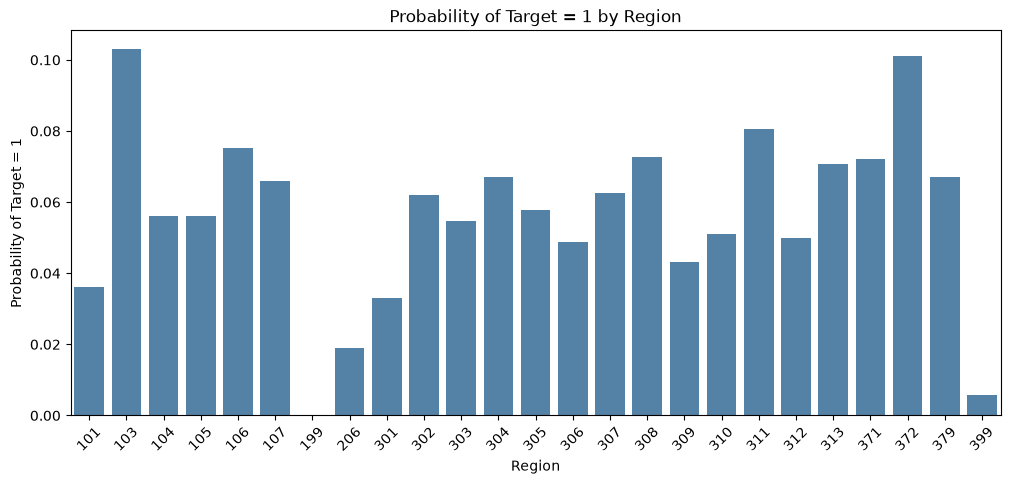

In [41]:
region_prob = (
    client_summary.groupby("region")["target"]
    .mean()
    .reset_index(name="probability")
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=region_prob,
    x="region",
    y="probability",
    color="steelblue"
)

plt.xlabel("Region")
plt.ylabel("Probability of Target = 1")
plt.title("Probability of Target = 1 by Region")
plt.xticks(rotation=45)
plt.show()
#region_prob

In [42]:
# Categorize regions into 4 risk classes
region_prob["region_risk"] = pd.qcut(
    region_prob["probability"],
    q=4,
    labels=[0, 1, 2, 3]
)

# Add risk category to client_summary
client_summary = client_summary.merge(
    region_prob[["region", "region_risk"]],
    on="region",
    how="left",
    validate="many_to_one"
)

# Create dummy variables
region_dummies = pd.get_dummies(
    client_summary["region_risk"],
    prefix="region_risk",
    dtype=int
)

client_summary = pd.concat(
    [client_summary, region_dummies],
    axis=1
)

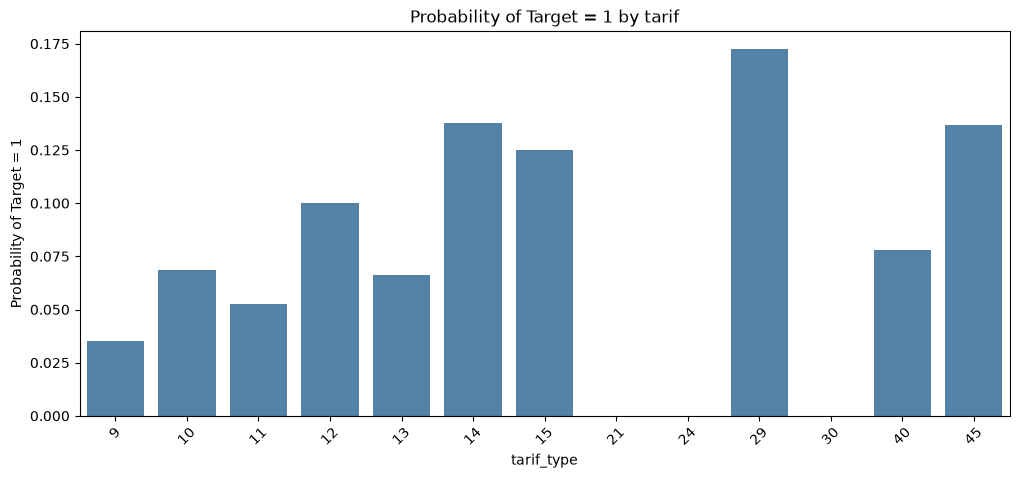

In [43]:
region_prob = (
    client_summary.groupby("tarif_type")["target"]
    .mean()
    .reset_index(name="probability")
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=region_prob,
    x="tarif_type",
    y="probability",
    color="steelblue"
)

plt.xlabel("tarif_type")
plt.ylabel("Probability of Target = 1")
plt.title("Probability of Target = 1 by tarif")
plt.xticks(rotation=45)
plt.show()
#region_prob

In [45]:
# 1. Calculate probability by tariff type
tarif_prob = (
    client_summary.groupby("tarif_type")["target"]
    .mean()
    .reset_index(name="probability")
)

# 2. Categorize tariffs into 4 risk groups
tarif_prob["tarif_risk"] = pd.qcut(
    tarif_prob["probability"],
    q=4,
    labels=[0, 1, 2, 3]
)

# 3. Merge using tarif_type
client_summary = client_summary.merge(
    tarif_prob[["tarif_type", "tarif_risk"]],
    on="tarif_type",
    how="left",
    validate="many_to_one"
)

# 4. Create 3 dummy variables (group 0 is reference)
tarif_dummies = pd.get_dummies(
    client_summary["tarif_risk"],
    prefix="tarif_risk",
    drop_first=True,
    dtype=int
)

client_summary = pd.concat(
    [client_summary, tarif_dummies],
    axis=1
)

# 5. Remove intermediate column
client_summary = client_summary.drop(columns=["tarif_risk"])

In [ ]:
client_summary = client_summary.drop(
    columns=["region_risk", "region_risk_0", "region", "client_id","tarif_type"]
)

client_summary.head()


,counter_statue,counter_code,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,client_catg,target,monthly_consumption,variability_index,region_risk_1,region_risk_2,region_risk_3,tarif_risk_1,tarif_risk_2,tarif_risk_3
0,0,203,1,352.400000,10.571429,0.000000,11,0.0,82.503571,11.147754,0,0,0,1,0,0
1,0,203,1,557.540541,0.000000,0.000000,11,0.0,129.405405,1.197241,0,1,0,1,0,0
2,0,203,1,798.611111,37.888889,0.000000,11,0.0,126.972222,4.344324,0,0,0,1,0,0
3,0,413,1,1.200000,0.000000,0.000000,11,0.0,0.300000,5.500444,1,0,0,1,0,0
4,0,207,1,663.714286,104.857143,117.357143,11,0.0,237.910714,3.574084,1,0,0,1,0,0


In [52]:
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    classification_report, recall_score
)


# Define target
y = client_summary["target"]

# Define features
X = client_summary.drop(
    columns=[ "target"],
    errors="ignore"
)

# Remove original region if using region-risk dummy variables
X = X.drop(columns=["region"], errors="ignore")

print("Features:", X.shape)
print("Target:", y.shape)

Features: (135011, 15)
Target: (135011,)


In [53]:
# Data Split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [54]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ),
        "params": {
            "model__C": [0.01, 0.1, 1, 10]
        },
        "scale": True
    },

    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {
            "model__n_neighbors": [5, 11, 21, 51],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        },
        "scale": True
    },

    "Decision Tree": {
        "model": DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ),
        "params": {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_leaf": [5, 20, 50],
            "model__min_samples_split": [2, 10, 20]
        },
        "scale": False
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=42,
            class_weight="balanced",
            n_jobs=1
        ),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [5, 10, None],
            "model__min_samples_leaf": [2, 10],
            "model__min_samples_split": [2, 10, 20]
        },
        "scale": False
    },

    "Voting Ensemble": {
        "model": VotingClassifier(
            estimators=[
                (
                    "lr",
                    Pipeline([
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                        ("model", LogisticRegression(
                            max_iter=2000,
                            class_weight="balanced"
                        ))
                    ])
                ),
                (
                    "knn",
                    Pipeline([
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                        ("model", KNeighborsClassifier())
                    ])
                ),
                (
                    "dt",
                    Pipeline([
                        ("imputer", SimpleImputer(strategy="median")),
                        ("model", DecisionTreeClassifier(
                            random_state=42,
                            class_weight="balanced"
                        ))
                    ])
                ),
                (
                    "rf",
                    Pipeline([
                        ("imputer", SimpleImputer(strategy="median")),
                        ("model", RandomForestClassifier(
                            random_state=42,
                            class_weight="balanced",
                            n_jobs=1
                        ))
                    ])
                )
            ],
            voting="soft"
        ),
        "params": {
            "model__weights": [
                [1, 1, 1, 1],
                [2, 1, 1, 2],
                [2, 1, 1, 3],
                [1, 1, 1, 3]
            ]
        },
        "scale": False
    },

    "Gradient Boosting": {
        "model": HistGradientBoostingClassifier(
            random_state=42
        ),
        "params": {
            "model__learning_rate": [0.03, 0.1],
            "model__max_iter": [100, 200],
            "model__max_leaf_nodes": [15, 31],
            "model__l2_regularization": [0, 1]
        },
        "scale": False
    }
}

In [56]:
import time
import pandas as pd

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

results = []
best_models = {}
grid_searches = {}

for name, config in models.items():

    print(f"\n{'=' * 55}")
    print(f"Training: {name}")
    print(f"{'=' * 55}")

    start_time = time.time()

    # Preprocessing
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if config["scale"]:
        steps.append(("scaler", StandardScaler()))

    steps.append(("model", config["model"]))

    pipeline = Pipeline(steps)

    # Hyperparameter tuning with cross-validation
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring={
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision"
        },
        refit="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=False,
        error_score="raise"
    )

    # Fit on training data only
    grid.fit(X_train, y_train)

    # Store best model and grid search
    best_models[name] = grid.best_estimator_
    grid_searches[name] = grid

    # Predict probabilities on test set
    y_prob = grid.predict_proba(X_test)[:, 1]

    # Best cross-validation results
    best_idx = grid.best_index_

    cv_roc_auc = grid.cv_results_[
        "mean_test_roc_auc"
    ][best_idx]

    cv_pr_auc = grid.cv_results_[
        "mean_test_pr_auc"
    ][best_idx]

    # Test results
    test_roc_auc = roc_auc_score(y_test, y_prob)
    test_pr_auc = average_precision_score(y_test, y_prob)

    elapsed = time.time() - start_time

    results.append({
        "Model": name,
        "CV ROC-AUC": cv_roc_auc,
        "CV PR-AUC": cv_pr_auc,
        "Test ROC-AUC": test_roc_auc,
        "Test PR-AUC": test_pr_auc,
        "Training Time (s)": round(elapsed, 2),
        "Best Parameters": grid.best_params_
    })

    print(f"CV ROC-AUC:   {cv_roc_auc:.4f}")
    print(f"CV PR-AUC:    {cv_pr_auc:.4f}")
    print(f"Test ROC-AUC: {test_roc_auc:.4f}")
    print(f"Test PR-AUC:  {test_pr_auc:.4f}")
    print(f"Time:         {elapsed:.1f} seconds")

# Results table
results_df = pd.DataFrame(results)

# Rank models using cross-validation performance
results_df = results_df.sort_values(
    "CV ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results_df)


Training: Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
CV ROC-AUC:   0.6412
CV PR-AUC:    0.0995
Test ROC-AUC: 0.6326
Test PR-AUC:  0.0928
Time:         14.3 seconds

Training: KNN
Fitting 5 folds for each of 16 candidates, totalling 80 fits
CV ROC-AUC:   0.6840
CV PR-AUC:    0.1223
Test ROC-AUC: 0.6857
Test PR-AUC:  0.1145
Time:         1243.6 seconds

Training: Decision Tree
Fitting 5 folds for each of 36 candidates, totalling 180 fits
CV ROC-AUC:   0.7096
CV PR-AUC:    0.1149
Test ROC-AUC: 0.7095
Test PR-AUC:  0.1118
Time:         19.9 seconds

Training: Random Forest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
CV ROC-AUC:   0.7457
CV PR-AUC:    0.1551
Test ROC-AUC: 0.7408
Test PR-AUC:  0.1464
Time:         257.3 seconds

Training: Voting Ensemble
Fitting 5 folds for each of 4 candidates, totalling 20 fits
CV ROC-AUC:   0.6955
CV PR-AUC:    0.1184
Test ROC-AUC: 0.6969
Test PR-AUC:  0.1070
Time:         230.1 seconds

Training: Gr

,Model,CV ROC-AUC,CV PR-AUC,Test ROC-AUC,Test PR-AUC,Training Time (s),Best Parameters
0,Gradient Boosting,0.753495,0.155022,0.753037,0.156844,44.25,"{'model__l2_regularization': 1, 'model__learni..."
1,Random Forest,0.745709,0.155139,0.740841,0.146414,257.32,"{'model__max_depth': 10, 'model__min_samples_l..."
2,Decision Tree,0.709629,0.114861,0.709527,0.111766,19.90,"{'model__max_depth': 5, 'model__min_samples_le..."
3,Voting Ensemble,0.695549,0.118391,0.696874,0.106976,230.12,"{'model__weights': [1, 1, 1, 3]}"
4,KNN,0.683999,0.122298,0.685696,0.114495,1243.57,"{'model__n_neighbors': 51, 'model__p': 1, 'mod..."
5,Logistic Regression,0.641177,0.099547,0.632583,0.092786,14.26,{'model__C': 10}


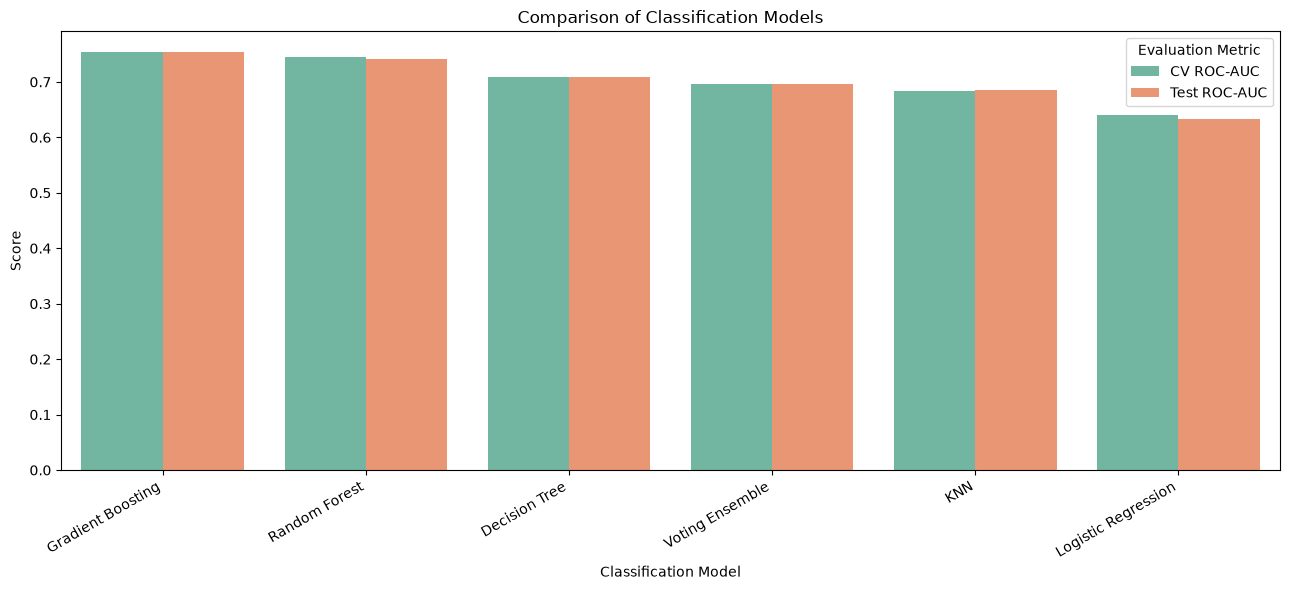

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reshape results for visualization
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["CV ROC-AUC", "Test ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)

plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.title("Comparison of Classification Models")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

## Feature Engineering

In [97]:
client_train = pd.read_csv(f'{TRAIN_DIR}/client_train.csv', low_memory=False)

In [98]:
#convert the column invoice_date to date time format on both the invoice train and invoice test
for df in [invoice_train, invoice_test]:
    df['invoice_date'] = pd.to_datetime(df['invoice_date'])
    
for df in [client_train, client_test]:
    df['creation_date'] = pd.to_datetime(df['creation_date'])

In [99]:
#encode labels in categorical column
d={"ELEC":0,"GAZ":1}
invoice_train['counter_type']=invoice_train['counter_type'].map(d)
invoice_test['counter_type']=invoice_test['counter_type'].map(d)

In [100]:
#convert categorical columns to int for model
client_train['client_catg'] = client_train['client_catg'].astype(int)
client_train['disrict'] = client_train['disrict'].astype(int)

client_test['client_catg'] = client_test['client_catg'].astype(int)
client_test['disrict'] = client_test['disrict'].astype(int)

In [101]:
invoice_test.groupby('client_id').size()

client_id
test_Client_0       37
test_Client_1       22
test_Client_10      74
test_Client_100     40
test_Client_1000    53
                    ..
test_Client_9995     4
test_Client_9996    46
test_Client_9997    59
test_Client_9998     1
test_Client_9999    33
Length: 58069, dtype: int64

In [102]:
def aggregate_by_client_id(invoice_data):
    aggs = {}
    aggs['consommation_level_1'] = ['mean']
    aggs['consommation_level_2'] = ['mean']
    aggs['consommation_level_3'] = ['mean']
    aggs['consommation_level_4'] = ['mean']

    agg_trans = invoice_data.groupby(['client_id']).agg(aggs)
    agg_trans.columns = ['_'.join(col).strip() for col in agg_trans.columns.values]
    agg_trans.reset_index(inplace=True)

    df = (invoice_data.groupby('client_id')
            .size()
            .reset_index(name='{}transactions_count'.format('1')))
    return pd.merge(df, agg_trans, on='client_id', how='left')

In [103]:
#group invoice data by client_id
agg_train = aggregate_by_client_id(invoice_train)

In [104]:
print(agg_train.shape)
agg_train.head()

(135493, 6)


,client_id,1transactions_count,consommation_level_1_mean,consommation_level_2_mean,consommation_level_3_mean,consommation_level_4_mean
0,train_Client_0,35,352.400000,10.571429,0.000000,0.000000
1,train_Client_1,37,557.540541,0.000000,0.000000,0.000000
2,train_Client_10,18,798.611111,37.888889,0.000000,0.000000
3,train_Client_100,20,1.200000,0.000000,0.000000,0.000000
4,train_Client_1000,14,663.714286,104.857143,117.357143,36.714286


In [105]:
#merge aggregate data with client dataset
train = pd.merge(client_train,agg_train, on='client_id', how='left')

In [106]:
#aggregate test set
agg_test = aggregate_by_client_id(invoice_test)
test = pd.merge(client_test,agg_test, on='client_id', how='left')

In [107]:
train.shape, test.shape

((135493, 11), (58069, 10))

In [108]:
#drop redundant columns
sub_client_id = test['client_id']
drop_columns = ['client_id', 'creation_date']

for col in drop_columns:
    if col in train.columns:
        train.drop([col], axis=1, inplace=True)
    if col in test.columns:
        test.drop([col], axis=1, inplace=True)

# Modelling

## Train LGBM *Classifier*

In [30]:
x_train = train.drop(columns=['target'])
y_train = train['target']

In [ ]:
model = LGBMClassifier(boosting_type='gbdt', num_iterations=500)
model.fit(x_train, y_train)

[LightGBM] [Warning] Unknown parameter: num_iterationss
[LightGBM] [Warning] Unknown parameter: num_iterationss
[LightGBM] [Info] Number of positive: 7566, number of negative: 127927
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002605 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1296
[LightGBM] [Info] Number of data points in the train set: 135493, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.055841 -> initscore=-2.827795
[LightGBM] [Info] Start training from score -2.827795


,num_iterationss,500
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [32]:
x_train.disrict.unique()

array([60, 69, 62, 63])

## Make Predictions on test set

In [33]:
test.columns

Index(['disrict', 'client_catg', 'region', '1transactions_count',
       'consommation_level_1_mean', 'consommation_level_2_mean',
       'consommation_level_3_mean', 'consommation_level_4_mean'],
      dtype='str')

In [34]:
preds = model.predict(test)
preds = pd.DataFrame(preds, columns=['target'])
preds.head()

[LightGBM] [Warning] Unknown parameter: num_iterationss


,target
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


In [35]:
submission = pd.DataFrame(
    {
        'client_id': sub_client_id,
        'target': preds['target']
    }
)

submission.head()

,client_id,target
0,test_Client_0,0.0
1,test_Client_1,0.0
2,test_Client_10,0.0
3,test_Client_100,0.0
4,test_Client_1000,0.0


In [36]:
submission.to_csv(f'{OUTPUT_DIR}/submission.csv', index=False)

## Tips 
- Thorough EDA and incorporating domain knowledge
- Re-grouping categorical features
- More feature engineering(try utilizing some date-time features)
- Target balancing - oversampling, undersampling, SMOTE, scale_pos_weight
- Model ensembling
- Train-test split or cross-validation


# ******************* GOOD LUCK!!! ***************************